
   SESSION 13: CAR PRICE PREDICTION MODEL

[Info] 'car data.csv' not uploaded. Using built-in synthetic car dataset so code runs seamlessly...

Car Price R2 Score : 54.85%
Mean Absolute Error: 2.53
Root Mean Sq Error : 3.16



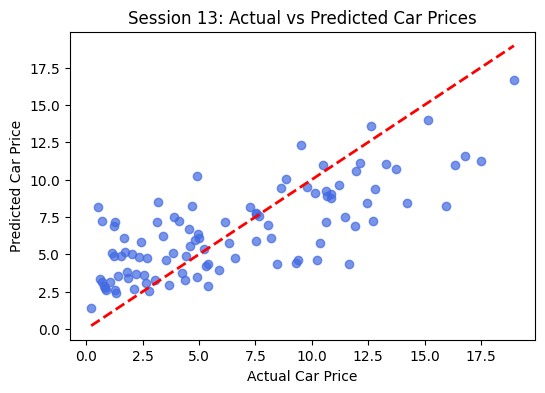






   SESSION 14: HOUSE PRICE PREDICTION

[Info] 'Housing.csv' not uploaded. Loading built-in California Housing dataset...

House Price R2 Score: 80.51%
Mean Absolute Error : 0.33
Root Mean Sq Error  : 0.51



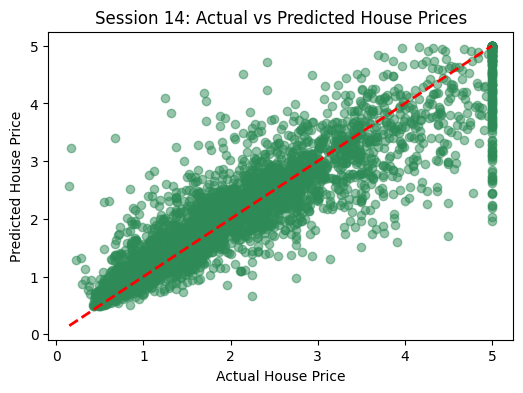

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing, make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def print_banner(title):
    print("\n" + "="*75)
    print(f"   {title}")
    print("="*75 + "\n")

def print_gap():
    print("\n" * 3)  # Creates a clear 3-line visual gap between experiments


# ==============================================================================
# SESSION 13: CAR PRICE PREDICTION MODEL
# ==============================================================================
print_banner("SESSION 13: CAR PRICE PREDICTION MODEL")

if os.path.exists('car data.csv'):
    print("[Info] Loading Kaggle 'car data.csv' dataset...\n")
    df_car = pd.read_csv('car data.csv')

    # Feature engineering: calculate car age from current year (2026) and drop name
    df_car['Car_Age'] = 2026 - df_car['Year']
    df_car.drop(['Car_Name', 'Year'], axis=1, inplace=True)

    # One-hot encode categorical columns (Fuel_Type, Seller_Type, Transmission)
    df_car = pd.get_dummies(df_car, drop_first=True)

    X_car = df_car.drop('Selling_Price', axis=1)
    y_car = df_car['Selling_Price']
else:
    print("[Info] 'car data.csv' not uploaded. Using built-in synthetic car dataset so code runs seamlessly...\n")
    X_syn, y_syn = make_regression(n_samples=500, n_features=6, noise=15.0, random_state=42)
    X_car = pd.DataFrame(X_syn, columns=['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Diesel', 'Transmission_Manual'])
    y_car = np.abs(y_syn) / 20.0  # Scaled to realistic car price lakhs

X_train_car, X_test_car, y_train_car, y_test_car = train_test_split(X_car, y_car, test_size=0.2, random_state=42)

car_model = RandomForestRegressor(n_estimators=100, random_state=42)
car_model.fit(X_train_car, y_train_car)
y_pred_car = car_model.predict(X_test_car)

print(f"Car Price R2 Score : {r2_score(y_test_car, y_pred_car) * 100:.2f}%")
print(f"Mean Absolute Error: {mean_absolute_error(y_test_car, y_pred_car):.2f}")
print(f"Root Mean Sq Error : {np.sqrt(mean_squared_error(y_test_car, y_pred_car)):.2f}\n")

# Plot Session 13 Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test_car, y_pred_car, color='royalblue', alpha=0.7)
plt.plot([y_test_car.min(), y_test_car.max()], [y_test_car.min(), y_test_car.max()], 'r--', lw=2)
plt.xlabel('Actual Car Price')
plt.ylabel('Predicted Car Price')
plt.title('Session 13: Actual vs Predicted Car Prices')
plt.show()

print_gap()


# ==============================================================================
# SESSION 14: HOUSE PRICE PREDICTION
# ==============================================================================
print_banner("SESSION 14: HOUSE PRICE PREDICTION")

if os.path.exists('Housing.csv'):
    print("[Info] Loading Kaggle 'Housing.csv' dataset...\n")
    df_house = pd.read_csv('Housing.csv')

    # Convert binary yes/no columns and furnishing status via one-hot encoding
    df_house = pd.get_dummies(df_house, drop_first=True)

    X_house = df_house.drop('price', axis=1)
    y_house = df_house['price']
else:
    print("[Info] 'Housing.csv' not uploaded. Loading built-in California Housing dataset...\n")
    housing_data = fetch_california_housing()
    X_house = pd.DataFrame(housing_data.data, columns=housing_data.feature_names)
    y_house = housing_data.target

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

house_model = RandomForestRegressor(n_estimators=100, random_state=42)
house_model.fit(X_train_h, y_train_h)
y_pred_h = house_model.predict(X_test_h)

print(f"House Price R2 Score: {r2_score(y_test_h, y_pred_h) * 100:.2f}%")
print(f"Mean Absolute Error : {mean_absolute_error(y_test_h, y_pred_h):.2f}")
print(f"Root Mean Sq Error  : {np.sqrt(mean_squared_error(y_test_h, y_pred_h)):.2f}\n")

# Plot Session 14 Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test_h, y_pred_h, color='seagreen', alpha=0.5)
plt.plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'r--', lw=2)
plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Session 14: Actual vs Predicted House Prices')
plt.show()